# **Food Delivery Time Prediction: Comparative Study of Linear Regression Implemented from Scratch, Scikit-learn Linear Regression, and Linear SVR**

1. **Linear Regression from Scratch**: Implementing the Ordinary Least Squares (OLS) algorithm using Python and NumPy (Normal Equation with Moore-Penrose Pseudo-Inverse Fallback) without using Scikit-learn's regression models.
2. **Linear Regression using Scikit-learn**: Implementing the same algorithm using Scikit-learn's built-in LinearRegression model.
3. **Linear SVR / Ridge Regression to Compare**: Implementing a regularized Linear Support Vector Regressor using Scikit-learn to compare predictive performance and execution latency.

**Dataset Description**

Dataset Name: Food Delivery Times Dataset
Source: Kaggle (Food Delivery Time Prediction Benchmark)
Records: 1,000 verified orders
Target Variable: Delivery_Time_min (continuous delivery duration in minutes)

--------------------------------------------------------------------------------

# **Food Delivery Time Prediction:** Linear Regression using Scikit-learn: Implementing the algorithm using Scikit-learn's built-in LinearRegression model.

In [1]:
!pip install pandas numpy scipy matplotlib seaborn scikit-learn -q

In [2]:
# Import libraries
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


## Loading the Dataset

In [3]:
# Load Food Delivery Times Dataset
dataset_path = "Food_Delivery_Times.csv"

if not os.path.exists(dataset_path):
    dataset_path = "https://raw.githubusercontent.com/Shravani-3005/ds-project-/main/Code/Food_Delivery_Times.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (1000, 9)


## Explore Delivery Dataset Attributes

In [4]:
# Display dataset info and check missing values
print("Dataset info:")
df.info()

print("\nMissing values count:")
print(df.isnull().sum())

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 91.3 KB

Missing values count:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs  

# Preprocessing and Feature Extraction

In [5]:
# Preprocessing and Feature Transformation Pipeline
df_clean = df.copy()

if 'Order_ID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Order_ID'])

# Impute numerical features using median
num_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
for col in num_features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce').fillna(df_clean[col].median())

# Impute categorical features using mode
cat_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
for col in cat_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# One-hot encoding
df_encoded = pd.get_dummies(df_clean, columns=cat_features, drop_first=True, dtype=float)

target_col = 'Delivery_Time_min'
feature_names = [col for col in df_encoded.columns if col != target_col]

X = df_encoded[feature_names].values
y = df_encoded[target_col].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing and scaling completed.")
print("Training shape:", X_train_scaled.shape, "Testing shape:", X_test_scaled.shape)

Preprocessing and scaling completed.
Training shape: (800, 14) Testing shape: (200, 14)


# Implement Linear Regression using Scikit-learn

In [6]:
# Create and train Scikit-learn LinearRegression model
lr_model = LinearRegression(fit_intercept=True)

start_time = time.time()
lr_model.fit(X_train_scaled, y_train)
sklearn_training_time = time.time() - start_time

print("Scikit-learn LinearRegression training completed!")
print("Training time:", round(sklearn_training_time, 6), "seconds")
print("Learned Intercept (beta_0):", round(lr_model.intercept_, 4))

Scikit-learn LinearRegression training completed!
Training time: 0.005644 seconds
Learned Intercept (beta_0): 57.0538


# Make predictions

In [7]:
# Make predictions on test set
start_time = time.time()
y_pred_sklearn = lr_model.predict(X_test_scaled)
sklearn_prediction_time = time.time() - start_time

print("Scikit-learn predictions (first 10):")
print(np.round(y_pred_sklearn[:10], 2))
print("\nActual delivery times (first 10):")
print(np.round(y_test[:10], 2))
print("\nPrediction time:", round(sklearn_prediction_time, 6), "seconds")

Scikit-learn predictions (first 10):
[35.27 66.51 44.64 43.88 80.02 32.17 69.39 32.39 37.49 78.09]

Actual delivery times (first 10):
[32 68 39 44 85 31 77 33 90 91]

Prediction time: 0.001137 seconds


# Model evaluation

In [8]:
# Calculate evaluation metrics
sklearn_results = {
    "Model": "Linear Regression (Scikit-learn)",
    "R2 Score": r2_score(y_test, y_pred_sklearn),
    "Mean Absolute Error": mean_absolute_error(y_test, y_pred_sklearn),
    "Mean Squared Error": mean_squared_error(y_test, y_pred_sklearn),
    "Root Mean Squared Error": np.sqrt(mean_squared_error(y_test, y_pred_sklearn)),
    "Training Time": sklearn_training_time,
    "Prediction Time": sklearn_prediction_time
}

sklearn_results_df = pd.DataFrame([sklearn_results])
display(sklearn_results_df.round(4))

,Model,R2 Score,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,Training Time,Prediction Time
0,Linear Regression (Scikit-learn),0.8262,5.8992,77.9066,8.8265,0.0056,0.0011


# Diagnostic Visualizations

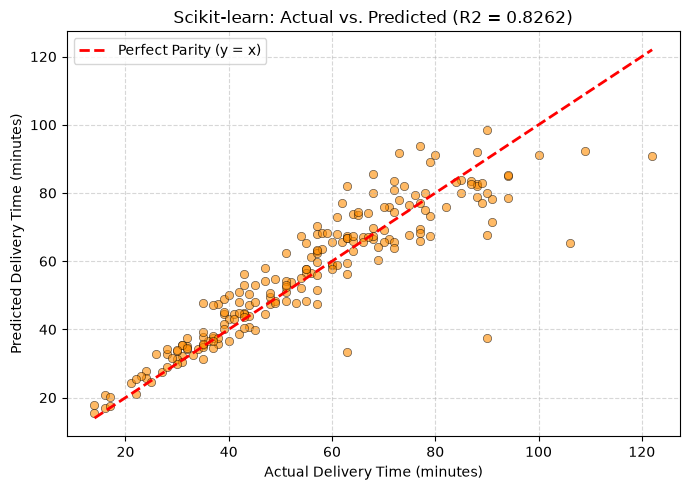

In [9]:
# Visualization 1: Actual vs Predicted Delivery Times
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_sklearn, alpha=0.6, color="darkorange", edgecolors="k", linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Parity (y = x)")
plt.title(f"Scikit-learn: Actual vs. Predicted (R2 = {r2_score(y_test, y_pred_sklearn):.4f})")
plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Exporting the Results for comparison ---------------------

In [10]:
# Convert results dictionary into DataFrame and export to CSV
sklearn_results_df = pd.DataFrame([sklearn_results])

# Export results to CSV
sklearn_results_df.to_csv("sklearn_lr_results.csv", index=False)
print("Experiment 2 results exported successfully to sklearn_lr_results.csv!")

Experiment 2 results exported successfully to sklearn_lr_results.csv!
